# Example 2: Genome-Scale GC Skew — E. coli K-12 MG1655


Fetch the complete E. coli K-12 MG1655 chromosome (NC_000913.3) and compute sliding-window GC skew to locate the replication origin signal.



Genome length: 4,641,652 bp


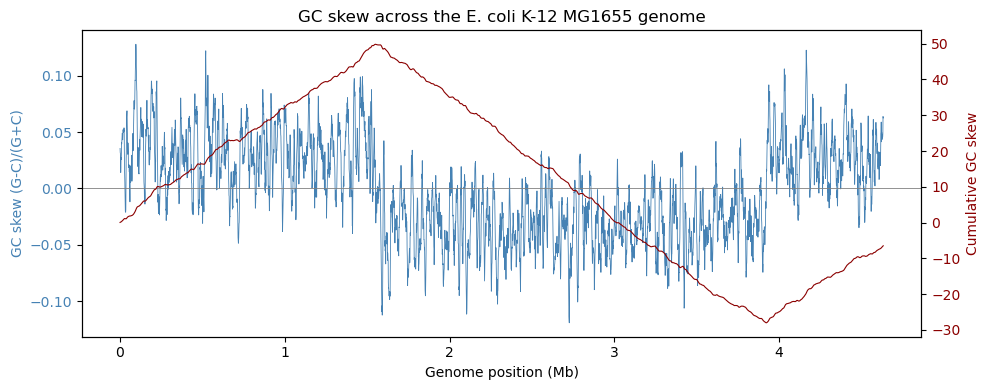

Saved: results/example2_gc_skew.png, results/example2_gc_skew_data.csv


In [2]:
# Fetch the full E. coli K-12 MG1655 genome and compute GC skew in sliding windows
import csv
import os
import matplotlib.pyplot as plt
from Bio import Entrez, SeqIO

os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)

Entrez.email = "your.example@institution.edu"
# this is a ~4.6 Mb fetch — expect it to take a little longer than a single-gene call


handle = Entrez.efetch(db="nucleotide", id="NC_000913.3", rettype="fasta", retmode="text")
record = SeqIO.read(handle, "fasta")
handle.close()
print(f"Genome length: {len(record.seq):,} bp")

# Sliding, overlapping 10,000 bp windows with a 1,000 bp step
window = 10_000
step = 1_000
positions, skews, cumulative_skews = [], [], []
cum_sum = 0.0
for start in range(0, len(record.seq) - window, step):
    chunk = record.seq[start:start + window]
    g, c = chunk.count("G"), chunk.count("C")
    if g + c == 0:
        continue
    skew = (g - c) / (g + c)
    skews.append(skew)
    positions.append(start)
    cum_sum += skew
    cumulative_skews.append(cum_sum)

# Save the raw data for reproducibility
with open("results/example2_gc_skew_data.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["position_bp", "gc_skew", "cumulative_gc_skew"])
    writer.writerows(zip(positions, skews, cumulative_skews))

# Plot and save
fig, ax1 = plt.subplots(figsize=(10, 4))
# Instantaneous GC skew on the left axis
ax1.plot([p / 1_000_000 for p in positions], skews,
         linewidth=0.6, color="steelblue", label="GC skew")
ax1.axhline(0, color="gray", linewidth=0.6)
ax1.set_xlabel("Genome position (Mb)")
ax1.set_ylabel("GC skew (G-C)/(G+C)", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")
# Cumulative GC skew on the right axis
ax2 = ax1.twinx()
ax2.plot([p / 1_000_000 for p in positions], cumulative_skews,
         linewidth=0.8, color="darkred", label="Cumulative GC skew")
ax2.set_ylabel("Cumulative GC skew", color="darkred")
ax2.tick_params(axis="y", labelcolor="darkred")

plt.title("GC skew across the E. coli K-12 MG1655 genome")
plt.tight_layout()
plt.savefig("results/example2_gc_skew.png", dpi=150)
plt.show()
print("Saved: results/example2_gc_skew.png, results/example2_gc_skew_data.csv")